# Simulate closed-loop
After implementing your control functionality, you can simulate the closed-loop with code that looks something like this...

Loading the supplied mission, running the PD-controlled submarine simulation,
and plotting the trajectory against the reference and cave boundaries.

This demonstration uses zero external disturbance.

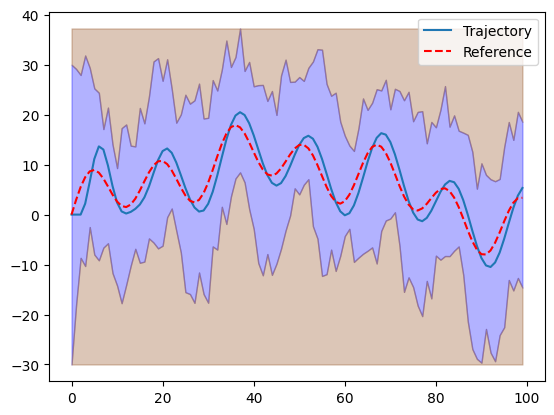

In [1]:
from pathlib import Path
import sys
import numpy as np

project_root = Path.cwd()
if not (project_root / "uuv_mission").is_dir():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from uuv_mission.control import PDController
from uuv_mission.dynamic import Mission, Submarine, ClosedLoop

mission = Mission.from_csv(project_root / "data" / "mission.csv")

submarine = Submarine()
controller = PDController()
closed_loop = ClosedLoop(submarine, controller)

disturbances = np.zeros(len(mission.reference))
trajectory = closed_loop.simulate(mission, disturbances)

trajectory.plot_completed_mission(mission)